In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

df = pd.read_csv("data/KTFGHU14.csv", sep=";")
df.shape

(4000, 23)

## Séance 2 – Analyse bivariée : catégorielle × catégorielle (Yassine)

**Variables catégorielles :** Gender, Region, CityCode et ProvPur (la cible).

**Méthode :** pour chaque paire de variables catégorielles :
1. **Table de contingence** : on compte les clients dans chaque combinaison de catégories.
2. **Test du χ²** : le lien est-il **réel** ou dû au hasard ? (significatif si p-value < 0,05)
3. **V de Cramér** : quelle est la **force** du lien ? De 0 (aucun lien) à 1 (lien total).

**Idée :** si les pourcentages sont les mêmes dans tous les groupes, connaître une variable n'aide pas à deviner l'autre (V ≈ 0). S'ils sont très différents, elle aide beaucoup (V ≈ 1).

In [14]:
def cramer_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, ddl, attendus = chi2_contingency(table, correction=False)
    n = table.values.sum()
    k = min(table.shape)
    V = np.sqrt(chi2 / (n * (k - 1)))
    return chi2, p, V

cramer_v(df["Gender"], df["ProvPur"])

(np.float64(14.083974841698417),
 np.float64(0.0001748269538529196),
 np.float64(0.059337961798705256))

In [15]:
var_cat = ["Gender", "Region", "CityCode", "ProvPur"]

resultats = []
for i in range(len(var_cat)):
    for j in range(i + 1, len(var_cat)):
        a, b = var_cat[i], var_cat[j]
        chi2, p, V = cramer_v(df[a], df[b])
        resultats.append({
            "paire": f"{a} × {b}",
            "chi2": round(chi2, 1),
            "p-value": round(p, 4),
            "V de Cramér": round(V, 3),
            "significatif (p<0,05)": "oui" if p < 0.05 else "non",
        })

tableau_v = pd.DataFrame(resultats).sort_values("V de Cramér", ascending=False).reset_index(drop=True)
tableau_v

,paire,chi2,p-value,V de Cramér,"significatif (p<0,05)"
0,Region × CityCode,11709.0,0.0000,1.000,oui
1,Gender × CityCode,19.9,0.3394,0.071,non
2,Gender × ProvPur,14.1,0.0002,0.059,oui
3,CityCode × ProvPur,12.9,0.7985,0.057,non
4,Gender × Region,3.0,0.3852,0.028,non
5,Region × ProvPur,2.0,0.5756,0.022,non


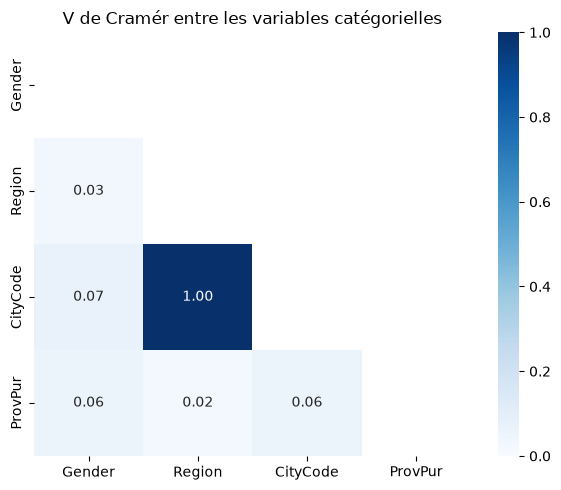

In [16]:
matrice = pd.DataFrame(index=var_cat, columns=var_cat, dtype=float)
for a in var_cat:
    for b in var_cat:
        matrice.loc[a, b] = cramer_v(df[a], df[b])[2]

masque = np.triu(np.ones_like(matrice, dtype=bool))

plt.figure(figsize=(6, 5))
sns.heatmap(matrice, mask=masque, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("V de Cramér entre les variables catégorielles")
plt.tight_layout()
plt.show()

In [17]:
pd.crosstab(df["CityCode"], df["Region"])

Region,NE,NW,SE,SW
CityCode,,,,
A,0,0,205,0
B,0,0,199,0
C,0,0,219,0
D,192,0,0,0
E,206,0,0,0
F,216,0,0,0
G,0,0,0,187
H,0,0,0,213
I,223,0,0,0


In [18]:
genre = df["Gender"].map({0: "Femme", 1: "Homme"})

effectifs = pd.crosstab(genre, df["ProvPur"], margins=True, margins_name="Total")
pourcentages = (pd.crosstab(genre, df["ProvPur"], normalize="index",
                            margins=True, margins_name="Total") * 100).round(1)

resultat = pd.DataFrame({
    "Nb clients": effectifs["Total"],
    "Nb acheteurs (Yes)": effectifs["Yes"],
    "% acheteurs (Yes)": pourcentages["Yes"],
    "% non-acheteurs (No)": pourcentages["No"],
})
resultat.index.name = "Genre"
resultat

,Nb clients,Nb acheteurs (Yes),% acheteurs (Yes),% non-acheteurs (No)
Genre,,,,
Femme,2818,208,7.4,92.6
Homme,1182,130,11.0,89.0
Total,4000,338,8.5,91.6
